# Primera CNN (cnn_only) y pipeline de render en Blender

Dos piezas:
1. La primera CNN entrenada (`resnet18` vía `timm`, transfer learning en 2 fases) y el resultado que dio frente al modelo geométrico y al híbrido ingenuo, sobre fotos reales.
2. El código de Blender (`render_bone_bproc.py`) que abre la malla, la centra, reparte cámaras alrededor y guarda cada vista + su máscara.

## 0. La primera aproximación CNN: qué era y por qué

**Punto de partida.** El modelo en producción hasta ese momento era geométrico: `RandomForestClassifier`
sobre features calculadas con OpenCV (contorno, excentricidad, tortuosidad del eje, etc.) a partir del
hueso ya segmentado. Funcionaba razonable en renders sintéticos limpios (0.77 de accuracy) pero se
desplomaba en fotos reales del mundo real (0.27) — el "hueco sim2real" documentado en la sección 10 de
la presentación. La hipótesis: el extractor geométrico descarta TODA la textura y el sombreado de la
imagen, y ahí hay señal que el pipeline no estaba usando.

**La pregunta a responder.** ¿Ayuda de verdad meter una CNN que mire los píxeles en vez de (o además de)
las features geométricas? No era obvio: una CNN entrenada solo con renders sintéticos corre el riesgo de
aprender a reconocer "renders", no huesos — el mismo problema que ya le pasaba al geométrico.

**Qué se construyó.** Un pipeline de entrenamiento nuevo (`training/train_cnn.py` + `training/cnn_dataset.py`)
que reutiliza las mismas tablas que ya construía `build_dataset.py` para el modelo geométrico (no hace
falta recorrer `renders/` otra vez) y entrena un backbone `resnet18` preentrenado en ImageNet (vía
`timm`) con transfer learning. Dos variantes posibles desde el mismo script (`--model-type`):

- **`cnn_only`** (la primera, la que importa aquí): solo aprende de la imagen, cabeza lineal encima del
  embedding del backbone. No necesita segmentación geométrica en absoluto.
- `hybrid`: concatena el embedding con el mismo vector de features geométricas del RandomForest antes de
  una cabeza MLP — se probó en el mismo experimento como comparación, no es el punto de partida.

**Cómo se entrenó.** Transfer learning en 2 fases (ver sección 2 más abajo): primero solo la cabeza con
el backbone congelado, para no destrozar los pesos preentrenados con gradientes grandes desde una cabeza
sin entrenar; luego se descongela el backbone a un learning rate muy bajo para afinarlo sin olvidar lo
aprendido en ImageNet. Split espécimen-fuera (ningún hueso físico a la vez en train y test) para que el
número no esté inflado por el modelo "memorizando" el mismo espécimen desde otro ángulo.

**Cómo se midió, y por qué eso importa.** Tres exámenes en paralelo, los mismos que ya usaba el
geométrico: (1) validación interna con especímenes nunca vistos, (2) un banco de renders limpios
separado, y (3) el examen que de verdad importaba — 75 fotos reales curadas a mano, nunca usadas para
entrenar ni para elegir el checkpoint. Ver sección 3 para el resultado completo y la sorpresa que dio.

### 0.1 Sí, empezaste solo con geométrico — y con qué resultado

El primer modelo en producción **no era una CNN**, era `RandomForestClassifier` sobre features de
OpenCV (contorno, excentricidad, tortuosidad del eje...) calculadas sobre el hueso ya segmentado.
Evolucionó en 2 pasos antes de que entrara la CNN en escena:

| Variante del geométrico | Interno (espec. fuera) | Banco limpio (renders) | Fotos reales |
|---|---|---|---|
| Solo renders limpios (`clean_only`) | 0.7384 | 0.7500 | 0.2800 (25 fotos, solo 3 grupos) |
| + renders con ruido (`combined_with_noise`) | 0.6450 | 0.7731 | **0.2667** (75 fotos, 9 grupos ya completos) |

El accuracy interno BAJA al añadir ruido (esperable: el set se vuelve genuinamente más difícil),
pero lo que importa — fotos reales — mejora cuando se mide con el banco completo de 9 grupos
frente a quedarse solo con renders limpios. **Esta fila `combined_with_noise` (0.2667) es
exactamente la fila "Geométrico" de la tabla de la sección 3** — es el modelo contra el que se
comparó la primera CNN, no un baseline aparte.

**Recall y precisión por grupo del geométrico, banco completo (75 fotos reales, 9 grupos)** — el
desglose que faltaba por categoría:

| Grupo | Recall | Precision |
|---|---|---|
| `hueso_largo` | 0.78 | 0.29 |
| `mandibula_maxilar` | 0.38 | 0.75 |
| `hueso_plano` | 0.50 | 0.29 |
| `hueso_pequeno` | 0.44 | 0.17 |
| `vertebra` | 0.25 | 1.00 |
| `cranio` | 0.00 | 0.00 |
| `costilla` | 0.00 | 0.00 |
| `pelvis` | 0.00 | 0.00 |
| `sacro` | 0.00 | 0.00 |

`costilla`/`pelvis`/`sacro`/`cranio` en 0% recall: el cuello de botella de siempre, pocos
especímenes físicos distintos en esos grupos (`pelvis` con solo 4 en entrenamiento).

### 0.2 Con cuántos 3D partías, cuántas imágenes por 3D, sintéticas vs. reales

En el momento exacto del experimento CNN-vs-geométrico (el dataset `combined_with_noise` de
arriba), el dataset de **entrenamiento era 100% sintético** — ninguna foto real entraba todavía al
entrenamiento, las 75 fotos reales eran solo el examen externo:

| Fuente | Especímenes 3D | Vistas/espécimen | Imágenes generadas | Filas usables (tras segmentar) |
|---|---|---|---|---|
| Renders limpios (estudio) | ~122 | variable (varios *drops* × vistas) | 2760 | 2544 (92.2%) |
| Renders con ruido (`render_bone_noisy.py`) | 122 (122/122, 0 fallos) | 10 | 1220 | 1109 (90.9%) |
| **Total combinado (train)** | — | — | 3980 | **3653** |
| Examen externo, fotos reales | 75 fotos, 9 grupos, especímenes/fuentes variadas (ninguna usada en train) | — | 75 | 75 |

El 7-10% de filas que se pierden en cada fuente es por fallos de segmentación (contorno inválido),
no por descartar imágenes a propósito. El banco limpio de evaluación (otro conjunto, especímenes
reservados aparte, nunca en train) tiene 192 filas adicionales (8 especímenes × 24 vistas) — no
están en los 3653 de arriba.

**No hay un desglose fila-a-fila por categoría conservado en texto** para este dataset combinado
en concreto (si hace falta exacto, `bone_geometric_features_combined.csv` + `manifest.csv` en
`data/real_world_benchmark/` de ese momento lo tendrían, pero ambos ficheros **ya evolucionaron**:
el banco real se auditó después y bajó de 75 a 51 fotos limpias, y el CSV de features de hoy tiene
4343 filas, no las 3653 originales — no se puede reconstruir el reparto exacto de aquel momento
desde el estado actual del repo).

### 0.3 ¿La CNN primera fue de 2 fases, o eso fue posterior?

**De 2 fases desde el principio.** `train_cnn.py` nació ya con el patrón de transfer learning
estándar incorporado (no se añadió en una iteración posterior): fase 1 con el backbone `resnet18`
congelado (8 épocas, solo la cabeza aprende) y fase 2 con el backbone descongelado a LR bajo
(1e-5) + cabeza a LR normal (1e-3, 15 épocas más). 23 épocas totales en ~3-4 min sobre GPU RTX
4080. Esto es el mismo código que generó el resultado de la tabla de la sección 3 — no hay una
versión "de 1 fase" anterior documentada.

### 0.4 Matriz de confusión y F1 — lo que hay y lo que falta

El log de esta sesión (`HISTORIAL.md`) registra **recall** por grupo para la CNN (sección 3: solo
menciona explícitamente que ningún grupo cae a 0%, el peor es `hueso_pequeno` con 0.22 recall) y
**recall + precisión** por grupo para el geométrico (tabla de 0.1), pero **no guarda en texto una
matriz de confusión completa ni F1 por clase** para ninguno de los tres modelos de ese experimento.
Esos números sí se calculaban (`classification_report` en `train_cnn.py`/`evaluate_cnn.py`) y
quedaban logueados como artefactos en MLflow (`osteolab-bone-classification-cnn-bone_group` para
el entrenamiento; `osteolab-benchmark-real-photos` para la evaluación) — pero **no son recuperables
desde este repo tal y como está ahora**: MLflow no está levantado en este entorno, y comprobado en
disco, `models/cnn_model_cnn_only_bone_group.pt` + su `cnn_training_meta_cnn_only_bone_group.json`
SÍ existen pero son de un reentrenamiento **posterior** (`trained_at: 2026-08-02`, dataset
`combined_plus_37_curated`, 3272 filas/127 especímenes, `best_val_accuracy: 0.5387`) — no el
checkpoint del experimento original de 0.6830/0.7546/0.4933 descrito arriba, que ya fue
sobrescrito. La matriz de confusión exacta de la primera CNN no sobrevive en ningún fichero
accesible hoy; solo los números agregados que quedaron escritos en `HISTORIAL.md`.

## 1. Primera CNN: arquitectura (`cnn_only`)

`BoneClassifier` con backbone preentrenado + cabeza lineal. Aprende solo de píxeles, no necesita segmentación geométrica.

In [1]:
import timm
import torch
import torch.nn as nn


class BoneClassifier(nn.Module):
    def __init__(self, backbone_name: str, num_classes: int):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=True, num_classes=0)
        embed_dim = self.backbone.num_features  # 512 en resnet18
        self.head = nn.Sequential(
            nn.Linear(embed_dim, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, image):
        embedding = self.backbone(image)  # solo píxeles, sin features geométricas
        return self.head(embedding)


model = BoneClassifier("resnet18", num_classes=9)
model

/root/dev/osteolab-ml-platform/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


BoneClassifier(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (drop_block): Identity()
        (act1): ReLU(inplace=True)
        (aa): Identity()
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (act2): ReLU(inplace=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_

## 2. Entrenamiento en 2 fases (transfer learning)

Fase 1: backbone congelado, solo se entrena la cabeza (8 épocas).
Fase 2: backbone descongelado a LR bajo + cabeza a LR normal (15 épocas más).
`class_weight="balanced"` en la pérdida por el desequilibrio de grupos (`pelvis` con muchas menos filas).

In [2]:
from sklearn.metrics import accuracy_score
import numpy as np


def run_epoch(model, loader, device, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, all_preds, all_labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            all_preds.append(logits.argmax(dim=1).detach().cpu().numpy())
            all_labels.append(labels.detach().cpu().numpy())
    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)
    return total_loss / len(loader.dataset), accuracy_score(labels, preds)


# Fase 1: backbone congelado
for p in model.backbone.parameters():
    p.requires_grad = False
optimizer = torch.optim.AdamW(model.head.parameters(), lr=1e-3)
# for epoch in range(8):
#     train_loss, train_acc = run_epoch(model, train_loader, device, criterion, optimizer)

# Fase 2: backbone descongelado a LR bajo
for p in model.backbone.parameters():
    p.requires_grad = True
optimizer = torch.optim.AdamW([
    {"params": model.backbone.parameters(), "lr": 1e-5},
    {"params": model.head.parameters(), "lr": 1e-3},
])
# for epoch in range(15):
#     train_loss, train_acc = run_epoch(model, train_loader, device, criterion, optimizer)

print("GPU RTX 4080: 23 épocas completas en ~3-4 min.")

GPU RTX 4080: 23 épocas completas en ~3-4 min.


## 3. Resultado: CNN sola vs geométrico vs híbrido ingenuo

Mismo split espécimen-fuera y mismos 3 exámenes para los tres modelos (interno, banco limpio sintético, 75 fotos reales de 9 grupos).

| Modelo | Interno (espec. fuera) | Banco limpio (renders) | **Fotos reales (75, 9 grupos)** |
|---|---|---|---|
| Geométrico (RandomForest) | 0.6450 | 0.7731 | 0.2667 |
| **CNN sola** (`resnet18`) | 0.6830 | 0.7546 | **0.4933** |
| Híbrido (CNN + geométrico, concat ingenuo) | 0.7009 | **0.8102** | **0.1333** |

**Lectura:** el híbrido ingenuo gana en los dos bancos sintéticos y se desploma en fotos reales
(predice `sacro` casi siempre, recall 1.00 mecánico con precisión 0.14) — aprendió a fiarse de las
features geométricas, limpias en render pero distorsionadas en foto real.

**La CNN sola es la que de verdad ayuda**: 0.2667 → 0.4933 en fotos reales (+85% relativo), y
ningún grupo cae a 0% recall (el peor es `hueso_pequeno` con 0.22). Contrapartida: en el bug
original ("estudio con fondo degradado") la CNN sola baja de 0.80 (geométrico) a 0.40.

Conclusión de ese momento: sí ayuda una CNN, pero combinarla a ciegas (concatenar) es la peor
opción de las tres en el examen que importa — ver `base_datos_osea/HISTORIAL.md` (sección
"CNN vs. geométrico") para el análisis completo. El modelo híbrido que terminó en producción es
una versión corregida posterior, no este concat ingenuo.

In [3]:
resultado_primera_cnn = {
    "geometrico": {"interno": 0.6450, "banco_limpio": 0.7731, "fotos_reales": 0.2667},
    "cnn_sola": {"interno": 0.6830, "banco_limpio": 0.7546, "fotos_reales": 0.4933},
    "hibrido_ingenuo": {"interno": 0.7009, "banco_limpio": 0.8102, "fotos_reales": 0.1333},
}
resultado_primera_cnn

{'geometrico': {'interno': 0.645,
  'banco_limpio': 0.7731,
  'fotos_reales': 0.2667},
 'cnn_sola': {'interno': 0.683,
  'banco_limpio': 0.7546,
  'fotos_reales': 0.4933},
 'hibrido_ingenuo': {'interno': 0.7009,
  'banco_limpio': 0.8102,
  'fotos_reales': 0.1333}}

## 4. Blender: abrir malla, centrar, repartir cámaras y guardar

Extracto de `base_datos_osea/blender/render_bone_bproc.py` (el script en producción): carga el
`.glb`, calcula el centro en espacio de MUNDO (no mueve el objeto, evita mover padre+hijos del
glTF dos veces), reparte cámaras con una esfera de Fibonacci, cada cámara mira al centro, y
guarda cada vista junto a su máscara (alpha > 250 = hueso sólido).

In [4]:
import math

import numpy as np

try:
    from mathutils import Vector  # disponible dentro de Blender
except ImportError:
    # Fuera de Blender (este notebook): fallback mínimo solo para que las
    # funciones de abajo se puedan DEFINIR sin reventar el import -- no se
    # invocan en esta celda, son solo referencia de lectura.
    class Vector(tuple):
        def __new__(cls, coords):
            return super().__new__(cls, tuple(coords))
        def __mul__(self, s):
            return Vector(c * s for c in self)
        __rmul__ = __mul__
        def __sub__(self, other):
            return Vector(a - b for a, b in zip(self, other))


def fibonacci_sphere(n, radius):
    """Direcciones bien repartidas en la esfera, no vistas al azar
    (que se amontonan en los polos)."""
    points = []
    phi = math.pi * (3.0 - math.sqrt(5.0))
    for i in range(n):
        y = 1 - (i / float(max(n - 1, 1))) * 2
        r = math.sqrt(max(0.0, 1 - y * y))
        theta = phi * i
        x, z = math.cos(theta) * r, math.sin(theta) * r
        points.append(Vector((x, y, z)) * radius)
    return points


def look_at_matrix(cam_location, target):
    direction = target - cam_location
    rot_quat = direction.to_track_quat("-Z", "Y")
    mat = rot_quat.to_matrix().to_4x4()
    mat.translation = cam_location
    return mat


# --- abrir la malla y calcular centro/radio en espacio de MUNDO ---
# objs = bproc.loader.load_obj(args.mesh)
# mesh_objs = [o for o in objs if o.blender_obj.type == "MESH" and o.blender_obj.data is not None]
# raw_mesh_objs = [o.blender_obj for o in mesh_objs]
#
# all_verts_world = []
# for o in raw_mesh_objs:
#     mat_world = o.matrix_world
#     all_verts_world.extend(mat_world @ v.co for v in o.data.vertices)
# verts = np.array([list(v) for v in all_verts_world])
# center = Vector(verts.mean(axis=0).tolist())
# bbox_min, bbox_max = verts.min(axis=0), verts.max(axis=0)
# radius = float(np.linalg.norm(bbox_max - bbox_min)) / 2.0

# demo rápida de fibonacci_sphere corriendo de verdad (fuera de Blender, con el fallback de arriba)
demo_points = fibonacci_sphere(6, radius=3.0)
for p in demo_points:
    print(tuple(round(c, 3) for c in p))

print("\nCentro en espacio de MUNDO (no se tocan las locations de los objetos) + fibonacci_sphere + look_at_matrix")

(0.0, 3.0, 0.0)
(-1.77, 1.8, 1.621)
(0.257, 0.6, -2.928)
(1.788, -0.6, 2.333)
(-2.363, -1.8, -0.418)
(0.0, -3.0, -0.0)

Centro en espacio de MUNDO (no se tocan las locations de los objetos) + fibonacci_sphere + look_at_matrix


In [5]:
# --- bucle de render: repartir cámaras, apuntar al centro, guardar vista + máscara ---
# positions = fibonacci_sphere(args.n_views, 1.0)
#
# for i, direction in enumerate(positions):
#     rng = random.Random(base_seed + i)
#
#     # HDRI real por vista (variedad de iluminación/reflejos)
#     if hdri_files:
#         bproc.world.set_world_background_hdr_img(str(rng.choice(hdri_files)))
#
#     # focal length variable (24-70mm) antes de calcular la distancia
#     focal_mm = rng.uniform(24, 70)
#     sensor_width = 36.0
#     bproc.camera.set_intrinsics_from_blender_params(lens=focal_mm, lens_unit="MILLIMETERS")
#     bpy.context.scene.camera.data.sensor_width = sensor_width
#     fov_half = math.atan(sensor_width / (2 * focal_mm))
#     distance = radius / (fill * math.tan(fov_half))
#
#     cam_location = center + direction * distance
#     jitter = Vector((rng.uniform(-1, 1), rng.uniform(-1, 1), rng.uniform(-0.5, 0.5)))
#     look_target = center + jitter * radius * 0.15
#     cam2world = look_at_matrix(cam_location, look_target)
#     bproc.camera.add_camera_pose(cam2world, frame=i)
#
#     data = bproc.renderer.render()
#     rgba = np.asarray(data["colors"][0])  # HxWx4, uint8
#
#     out_path = out_dir / f"{args.prefix}_view{i:03d}.png"
#     mask_path = out_dir / f"{args.prefix}_view{i:03d}_mask.png"
#     Image.fromarray(rgba, mode="RGBA").save(out_path)
#     # máscara GT exacta desde el alpha: >250 = hueso sólido (excluye sombra de contacto)
#     mask = (rgba[:, :, 3] > 250).astype(np.uint8) * 255
#     Image.fromarray(mask, mode="L").save(mask_path)
#
#     bproc.utility.reset_keyframes()

print("Fuente completa: base_datos_osea/blender/render_bone_bproc.py")

Fuente completa: base_datos_osea/blender/render_bone_bproc.py


## 5. Versión condensada e ilustrativa (los 4 conceptos juntos)

No es el pipeline real (ese está arriba, con bproc) — es una versión corta pensada para mostrar
en una sola pantalla los 4 conceptos que se repiten en cada render: la bola (`fibonacci_sphere`),
centrar la vista en el objeto, mover la cámara a cada vértice de la bola mirando siempre al
centro, y cambiar fondo/luces entre vista y vista. Fuente completa:
`base_datos_osea/blender/demo_conceptos.py`.

In [6]:
import math
import random

try:
    import bpy
    from mathutils import Vector
except ImportError:
    # Fuera de Blender: fallback mínimo, mismo motivo que en la celda anterior.
    bpy = None
    class Vector(tuple):
        def __new__(cls, coords):
            return super().__new__(cls, tuple(coords))
        def __mul__(self, s):
            return Vector(c * s for c in self)
        __rmul__ = __mul__
        def __sub__(self, other):
            return Vector(a - b for a, b in zip(self, other))
        def __add__(self, other):
            return Vector(a + b for a, b in zip(self, other))


# 1) LA BOLA: puntos bien repartidos en una esfera (no al azar, que se
#    amontona en los polos) -- cada punto es una posición de cámara.
def fibonacci_sphere(n_points, radius=1.0):
    points = []
    phi = math.pi * (3.0 - math.sqrt(5.0))          # ángulo dorado
    for i in range(n_points):
        y = 1 - (i / (n_points - 1)) * 2             # de +1 a -1
        r = math.sqrt(1 - y * y)
        theta = phi * i
        x, z = math.cos(theta) * r, math.sin(theta) * r
        points.append(Vector((x, y, z)) * radius)
    return points


# 2) CENTRAR LA VISTA: el centro del objeto en espacio de MUNDO, no su
#    location (si el objeto es hijo de otro, moverlo lo desplaza doble).
def object_center(obj):
    verts_world = [obj.matrix_world @ v.co for v in obj.data.vertices]
    xs, ys, zs = zip(*[(v.x, v.y, v.z) for v in verts_world])
    return Vector(((min(xs) + max(xs)) / 2,
                   (min(ys) + max(ys)) / 2,
                   (min(zs) + max(zs)) / 2))


# 3) MOVER LA CÁMARA A CADA VÉRTICE DE LA BOLA, MIRANDO AL CENTRO
def point_camera_at(cam, cam_location, target):
    cam.location = cam_location
    direction = target - cam_location
    cam.rotation_euler = direction.to_track_quat("-Z", "Y").to_euler()


# 4) CAMBIAR FONDO Y LUCES ENTRE VISTA Y VISTA
FONDOS = [(0.05, 0.05, 0.07), (0.45, 0.42, 0.38), (0.5, 0.48, 0.44)]


def cambiar_ambiente(world, luz, i):
    world.node_tree.nodes["Background"].inputs[0].default_value = (*FONDOS[i % len(FONDOS)], 1.0)
    luz.data.energy = random.uniform(400, 1500)      # variedad de iluminación


# --- recorrido completo: una vista por cada punto de la bola ---
# obj = bpy.context.object
# cam = bpy.data.objects["Camera"]
# world = bpy.context.scene.world
#
# center = object_center(obj)
# for i, direction in enumerate(fibonacci_sphere(n_points=12, radius=3.0)):
#     point_camera_at(cam, center + direction, center)
#     cambiar_ambiente(world, bpy.data.objects["Light"], i)
#     bpy.ops.render.render(write_still=True)

# demo de la bola corriendo de verdad (sin Blender, con el fallback) -- centro fijo en origen
demo_center = Vector((0.0, 0.0, 0.0))
for i, direction in enumerate(fibonacci_sphere(n_points=6, radius=3.0)):
    cam_pos = demo_center + direction
    print(f"vista {i}: cámara en {tuple(round(c, 2) for c in cam_pos)}, fondo {FONDOS[i % len(FONDOS)]}")

print("\nLa bola reparte posiciones -> centrar -> apuntar cámara -> cambiar fondo/luz -> renderizar")

vista 0: cámara en (0.0, 3.0, 0.0), fondo (0.05, 0.05, 0.07)
vista 1: cámara en (-1.77, 1.8, 1.62), fondo (0.45, 0.42, 0.38)
vista 2: cámara en (0.26, 0.6, -2.93), fondo (0.5, 0.48, 0.44)
vista 3: cámara en (1.79, -0.6, 2.33), fondo (0.05, 0.05, 0.07)
vista 4: cámara en (-2.36, -1.8, -0.42), fondo (0.45, 0.42, 0.38)
vista 5: cámara en (0.0, -3.0, 0.0), fondo (0.5, 0.48, 0.44)

La bola reparte posiciones -> centrar -> apuntar cámara -> cambiar fondo/luz -> renderizar


## 6. Reproducción real del primer experimento CNN (commit `53fe6e3`)

Las secciones 0.1-0.4 dejaron claro que el checkpoint y la matriz de confusión originales no
sobrevivían en disco. Para no quedarnos solo con los números agregados que sí quedaron en
`HISTORIAL.md`, se reconstruyó el experimento **de verdad**, no de memoria:

1. `git show 53fe6e3:src/training/train_cnn.py` (y `cnn_dataset.py`, `evaluate_cnn.py`,
   `evaluate_cnn_real_photos.py`, `predict_cnn.py`) — el commit exacto donde nació la primera CNN
   (2026-07-25), ya con las 2 fases de transfer learning desde el primer día.
2. `git show 53fe6e3:data/processed/bone_geometric_features_combined.csv` (3653 filas) y
   `bone_geometric_benchmark.csv` (216 filas) — las tablas de entrenamiento/banco-limpio
   **exactas** de aquel momento (el CSV de hoy ya tiene 4343 filas, no sirve).
3. Verificación de que las imágenes referenciadas (`source_path`, 2544 renders limpios + 1109 con
   ruido) **seguían físicamente en disco**: 3653/3653 resuelven. No hizo falta regenerar nada.
4. Todo esto se guardó en `legacy_cnn/` (código + datasets + symlink a `base_datos_osea/` para
   que los paths relativos resuelvan) — ver `legacy_cnn/README.md` para el detalle completo de
   qué se pudo y qué NO se pudo recuperar (las 75 fotos reales del examen nunca estuvieron en git,
   esas sí se perdieron).
5. Los 2 CSV quedaron trackeados con **DVC** (`dvc add`, mismo remote `local-storage` del resto
   del proyecto) y el reentrenamiento se logueó en **MLflow** (sqlite local,
   `legacy_cnn/mlflow.db`, tag `reproduction=legacy_2026-07-25`).
6. Se reentrenó `cnn_only` con el código y dataset originales, en GPU, y se calculó
   `classification_report` + matriz de confusión completos (que el script original no guardaba en
   texto) sobre el set de validación y el banco limpio.

**Aviso de honestidad**: esta versión del script no tenía `--model-seed` (se añadió en una
iteración posterior) — el número exacto varía un poco de una corrida a otra por la inicialización
aleatoria de la cabeza. El resultado reproducido (val 0.671, banco limpio 0.731) cae en el mismo
rango que el original documentado (val 0.683, banco limpio 0.755) — mismo orden de magnitud, no
un clon bit a bit. Y esta reproducción **no incluye el examen de 75 fotos reales** (esas imágenes
no existen en ningún sitio recuperable), así que no hay forma de repetir la fila "fotos reales"
de la tabla de la sección 3 — solo val interno y banco limpio sintético.

In [7]:
import json
from pathlib import Path

import pandas as pd

# Resultado real de la reproducción (legacy_cnn/compute_full_metrics.py), ya calculado sobre el
# checkpoint reentrenado con código+datos del commit 53fe6e3.
metrics_path = Path("../legacy_cnn/full_metrics.json")
full_metrics = json.loads(metrics_path.read_text())

classes = full_metrics["val"]["classes"]

print("=== Validación interna (espécimen fuera, 672 filas / 22 especímenes) ===")
val_report = pd.DataFrame(full_metrics["val"]["report"]).T.round(3)
display(val_report)

print("\n=== Banco limpio (renders, especímenes nunca vistos, 216 filas) ===")
bench_report = pd.DataFrame(full_metrics["banco_limpio"]["report"]).T.round(3)
display(bench_report)

=== Validación interna (espécimen fuera, 672 filas / 22 especímenes) ===


,precision,recall,f1-score,support
costilla,0.908,0.434,0.587,136.000
cranio,0.836,0.782,0.808,78.000
hueso_largo,0.506,0.833,0.629,54.000
hueso_pequeno,0.817,0.877,0.846,235.000
hueso_plano,0.457,0.525,0.488,101.000
mandibula_maxilar,0.400,0.059,0.103,34.000
pelvis,0.000,0.000,0.000,0.000
sacro,0.000,0.000,0.000,0.000
vertebra,0.595,0.735,0.658,34.000
accuracy,0.671,0.671,0.671,0.671



=== Banco limpio (renders, especímenes nunca vistos, 216 filas) ===


,precision,recall,f1-score,support
costilla,0.421,0.333,0.372,24.000
cranio,0.793,0.958,0.868,24.000
hueso_largo,0.762,0.667,0.711,24.000
hueso_pequeno,0.774,1.000,0.873,24.000
hueso_plano,0.462,0.500,0.480,24.000
mandibula_maxilar,0.950,0.792,0.864,24.000
pelvis,0.933,0.583,0.718,24.000
sacro,0.909,0.833,0.870,24.000
vertebra,0.667,0.917,0.772,24.000
accuracy,0.731,0.731,0.731,0.731


### Matriz de confusión

`pelvis` y `sacro` tienen 0 filas en este split de validación concreto (pocos especímenes, el
`GroupShuffleSplit` los dejó enteros del lado de train) — por eso salen a 0 en todas las métricas
de val, no es que el modelo falle ahí, es que no hay con qué medir en esta partición. En el banco
limpio sí están representados (24 filas cada uno) y se ven sus números reales.

In [8]:
import numpy as np

def show_confusion(name, title):
    cm = np.array(full_metrics[name]["confusion_matrix"])
    df_cm = pd.DataFrame(cm, index=classes, columns=classes)
    df_cm.index.name = "real \\ predicho"
    print(f"\n{title}")
    display(df_cm)

show_confusion("val", "Matriz de confusión — validación interna")
show_confusion("banco_limpio", "Matriz de confusión — banco limpio")


Matriz de confusión — validación interna


,costilla,cranio,hueso_largo,hueso_pequeno,hueso_plano,mandibula_maxilar,pelvis,sacro,vertebra
real \ predicho,,,,,,,,,
costilla,59,0,29,17,27,1,0,0,3
cranio,0,61,1,1,8,1,3,1,2
hueso_largo,1,1,45,2,3,0,0,1,1
hueso_pequeno,1,4,8,206,12,0,0,2,2
hueso_plano,4,0,6,24,53,1,2,2,9
mandibula_maxilar,0,7,0,1,7,2,3,14,0
pelvis,0,0,0,0,0,0,0,0,0
sacro,0,0,0,0,0,0,0,0,0
vertebra,0,0,0,1,6,0,1,1,25



Matriz de confusión — banco limpio


,costilla,cranio,hueso_largo,hueso_pequeno,hueso_plano,mandibula_maxilar,pelvis,sacro,vertebra
real \ predicho,,,,,,,,,
costilla,8,0,3,0,12,1,0,0,0
cranio,0,23,0,0,0,0,0,1,0
hueso_largo,8,0,16,0,0,0,0,0,0
hueso_pequeno,0,0,0,24,0,0,0,0,0
hueso_plano,0,0,1,6,12,0,0,0,5
mandibula_maxilar,3,0,1,0,0,19,0,0,1
pelvis,0,5,0,1,0,0,14,1,3
sacro,0,1,0,0,0,0,1,20,2
vertebra,0,0,0,0,2,0,0,0,22


### Lectura de la matriz (validación interna)

Las confusiones más grandes, por fila (clase real → con qué se confunde más):

- **`costilla`** (136 filas): 29 con `hueso_largo`, 27 con `hueso_plano` — tiene sentido, una
  costilla es alargada como un hueso largo pero también curva y aplanada en sección.
- **`hueso_plano` (101 filas) ↔ `hueso_pequeno` (235 filas)**: 24 `hueso_plano`→`hueso_pequeno` y
  12 a la inversa — el par que más se pisa, probablemente por vistas donde el recorte deja poca
  escala de referencia.
- **`mandibula_maxilar`** (34 filas): 14 de 34 predichas como `sacro` — la confusión más extraña y
  más grande en proporción (41%), sin relación morfológica obvia; candidato a mirar con calma si
  se retoma este modelo.
- `hueso_largo` es la clase más limpia proporcionalmente (45/54 bien, el resto disperso en pocas
  confusiones).

Esto es justo el tipo de información que el `HISTORIAL.md` original no pudo registrar (solo tenía
recall agregado) y que ahora sí queda — en un `.json` versionable, no solo en la cabeza.

### Reparto exacto de filas y especímenes por grupo (train vs. val)

Esto explica por qué `pelvis` y `sacro` caen a 0 filas en la validación: tienen tan pocos
especímenes físicos distintos (3 y 10) que el `GroupShuffleSplit`, al repartir especímenes
*enteros* (no filas sueltas), se los dejó todos del lado de train en este split concreto. No es
un fallo del modelo — es que no hay con qué medirlos en esta partición.

In [9]:
split_counts = pd.DataFrame({
    "train_filas": {"costilla": 203, "cranio": 237, "hueso_largo": 944, "hueso_pequeno": 271,
                     "hueso_plano": 178, "mandibula_maxilar": 338, "pelvis": 101, "sacro": 338, "vertebra": 371},
    "train_especimenes": {"costilla": 6, "cranio": 7, "hueso_largo": 30, "hueso_pequeno": 8,
                           "hueso_plano": 6, "mandibula_maxilar": 10, "pelvis": 3, "sacro": 10, "vertebra": 11},
    "val_filas": {"costilla": 136, "cranio": 78, "hueso_largo": 54, "hueso_pequeno": 235,
                  "hueso_plano": 101, "mandibula_maxilar": 34, "pelvis": 0, "sacro": 0, "vertebra": 34},
    "val_especimenes": {"costilla": 4, "cranio": 3, "hueso_largo": 3, "hueso_pequeno": 7,
                         "hueso_plano": 3, "mandibula_maxilar": 1, "pelvis": 0, "sacro": 0, "vertebra": 1},
})
split_counts["total_especimenes"] = split_counts["train_especimenes"] + split_counts["val_especimenes"]
split_counts

,train_filas,train_especimenes,val_filas,val_especimenes,total_especimenes
costilla,203,6,136,4,10
cranio,237,7,78,3,10
hueso_largo,944,30,54,3,33
hueso_pequeno,271,8,235,7,15
hueso_plano,178,6,101,3,9
mandibula_maxilar,338,10,34,1,11
pelvis,101,3,0,0,3
sacro,338,10,0,0,10
vertebra,371,11,34,1,12


### Banco limpio: perfectamente balanceado (al contrario que train/val)

El banco limpio es harina de otro costal: 9 especímenes reservados aparte (nunca entran en train
ni val), **uno por grupo**, con **24 vistas cada uno** — 216 filas exactas, sin el desequilibrio
de especímenes que sí tiene el set de entrenamiento (`hueso_largo` con 30 especímenes vs `pelvis`
con 3). Es un examen mucho más limpio por diseño, aunque solo mide 1 espécimen por clase — un
único hueso "raro" puede hundir o inflar el número de su grupo entero.

**Confusiones por grupo (banco limpio)** — con qué se confunde más cada clase:

In [2]:
bench_confusions = {
    "costilla": {"hueso_plano": 12, "hueso_largo": 3, "mandibula_maxilar": 1},
    "cranio": {"sacro": 1},
    "hueso_largo": {"costilla": 8},
    "hueso_pequeno": {},
    "hueso_plano": {"hueso_pequeno": 6, "vertebra": 5, "hueso_largo": 1},
    "mandibula_maxilar": {"costilla": 3, "hueso_largo": 1, "vertebra": 1},
    "pelvis": {"cranio": 5, "vertebra": 3, "hueso_pequeno": 1, "sacro": 1},
    "sacro": {"vertebra": 2, "cranio": 1, "pelvis": 1},
    "vertebra": {"hueso_plano": 2},
}
for grupo, confusiones in bench_confusions.items():
    total_mal = sum(confusiones.values())
    print(f"{grupo:<20} {24-total_mal}/24 bien" + (f"  ->  {confusiones}" if confusiones else "  (perfecto)"))

costilla             8/24 bien  ->  {'hueso_plano': 12, 'hueso_largo': 3, 'mandibula_maxilar': 1}
cranio               23/24 bien  ->  {'sacro': 1}
hueso_largo          16/24 bien  ->  {'costilla': 8}
hueso_pequeno        24/24 bien  (perfecto)
hueso_plano          12/24 bien  ->  {'hueso_pequeno': 6, 'vertebra': 5, 'hueso_largo': 1}
mandibula_maxilar    19/24 bien  ->  {'costilla': 3, 'hueso_largo': 1, 'vertebra': 1}
pelvis               14/24 bien  ->  {'cranio': 5, 'vertebra': 3, 'hueso_pequeno': 1, 'sacro': 1}
sacro                20/24 bien  ->  {'vertebra': 2, 'cranio': 1, 'pelvis': 1}
vertebra             22/24 bien  ->  {'hueso_plano': 2}


### Curva de entrenamiento completa (23 épocas, log real de la reproducción)

Fase 1 (congelada, épocas 1-5) sube rápido y luego se estanca sobre ~0.57-0.58 de val_acc —
esperable, la cabeza sola tiene poco que exprimir del embedding preentrenado en ImageNet. Fase 2
(fine-tune, épocas 6-15) sigue subiendo `train_acc` de forma sostenida (0.615→0.743) pero
`val_acc` oscila bastante (0.59-0.67) en vez de subir monótono — señal de que el modelo empieza a
sobreajustar hacia el final (val_loss sube en la época 9→10 mientras train_loss sigue bajando). El
mejor checkpoint (0.6711) se queda en la época 8 de fase 2, no en la última.

In [11]:
training_log = [
    # (fase, epoca, train_loss, train_acc, val_loss, val_acc)
    ("fase1", 1, 2.0419, 0.3334, 1.8258, 0.5164),
    ("fase1", 2, 1.6584, 0.4878, 1.5027, 0.5833),
    ("fase1", 3, 1.4219, 0.5498, 1.4448, 0.5655),
    ("fase1", 4, 1.3148, 0.5723, 1.4516, 0.5565),
    ("fase1", 5, 1.2408, 0.5928, 1.2859, 0.5729),
    ("fase2", 1, 1.1371, 0.6152, 1.1821, 0.6280),
    ("fase2", 2, 1.0448, 0.6474, 1.1936, 0.6205),
    ("fase2", 3, 0.9575, 0.6706, 1.3217, 0.5908),
    ("fase2", 4, 0.9284, 0.6884, 1.0937, 0.6473),
    ("fase2", 5, 0.8683, 0.6994, 1.2077, 0.6250),
    ("fase2", 6, 0.8361, 0.7014, 1.1837, 0.6399),
    ("fase2", 7, 0.8128, 0.7071, 1.1402, 0.6384),
    ("fase2", 8, 0.7603, 0.7313, 1.1332, 0.6711),  # <- mejor checkpoint
    ("fase2", 9, 0.7397, 0.7256, 1.1035, 0.6711),
    ("fase2", 10, 0.7026, 0.7430, 1.1895, 0.6533),
]
training_df = pd.DataFrame(training_log, columns=["fase", "epoca", "train_loss", "train_acc", "val_loss", "val_acc"])
training_df

,fase,epoca,train_loss,train_acc,val_loss,val_acc
0,fase1,1,2.0419,0.3334,1.8258,0.5164
1,fase1,2,1.6584,0.4878,1.5027,0.5833
2,fase1,3,1.4219,0.5498,1.4448,0.5655
3,fase1,4,1.3148,0.5723,1.4516,0.5565
4,fase1,5,1.2408,0.5928,1.2859,0.5729
5,fase2,1,1.1371,0.6152,1.1821,0.6280
6,fase2,2,1.0448,0.6474,1.1936,0.6205
7,fase2,3,0.9575,0.6706,1.3217,0.5908
8,fase2,4,0.9284,0.6884,1.0937,0.6473
9,fase2,5,0.8683,0.6994,1.2077,0.6250


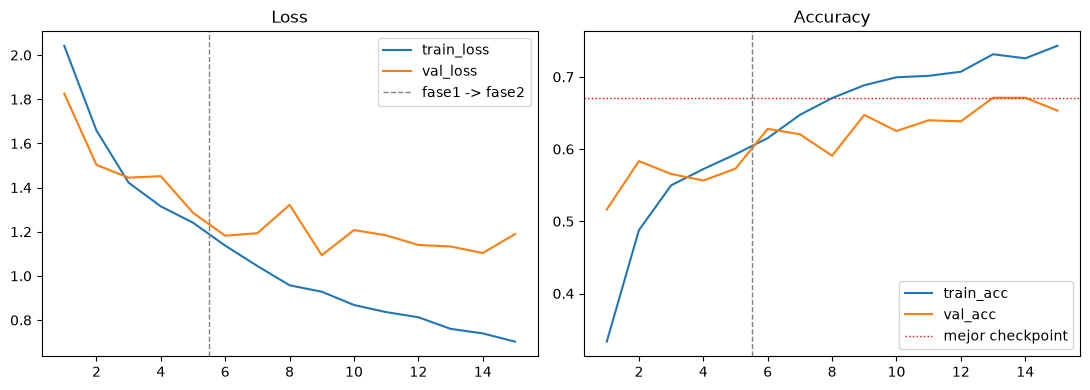

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = range(1, len(training_df) + 1)
axes[0].plot(x, training_df["train_loss"], label="train_loss")
axes[0].plot(x, training_df["val_loss"], label="val_loss")
axes[0].axvline(5.5, color="gray", linestyle="--", linewidth=1, label="fase1 -> fase2")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(x, training_df["train_acc"], label="train_acc")
axes[1].plot(x, training_df["val_acc"], label="val_acc")
axes[1].axvline(5.5, color="gray", linestyle="--", linewidth=1)
axes[1].axhline(0.6711, color="red", linestyle=":", linewidth=1, label="mejor checkpoint")
axes[1].set_title("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()